In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting configurations
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Path relative to the notebook folder
DATA_PATH = "../data/raw/Churn_Modelling.csv"

# Load raw banking data
df = pd.read_csv(DATA_PATH)

print(f"Dataset successfully loaded! Dimensions: {df.shape[0]} rows, {df.shape[1]} columns.\n")
df.head()

Dataset successfully loaded! Dimensions: 10000 rows, 13 columns.



,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,Num Of Products,Has Credit Card,Is Active Member,Estimated Salary,Churn
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
# 1. Inspect structural data types and memory footprint
print("=== DATAFRAME INFORMATION ===")
df.info()

print("\n=== MISSING / NULL VALUE COUNT ===")
print(df.isnull().sum())

print("\n=== DUPLICATE RECORDS ===")
print(f"Total duplicate rows: {df.duplicated().sum()}")

=== DATAFRAME INFORMATION ===
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerId        10000 non-null  int64  
 1   Surname           10000 non-null  str    
 2   CreditScore       10000 non-null  int64  
 3   Geography         10000 non-null  str    
 4   Gender            10000 non-null  str    
 5   Age               10000 non-null  int64  
 6   Tenure            10000 non-null  int64  
 7   Balance           10000 non-null  float64
 8   Num Of Products   10000 non-null  int64  
 9   Has Credit Card   10000 non-null  int64  
 10  Is Active Member  10000 non-null  int64  
 11  Estimated Salary  10000 non-null  float64
 12  Churn             10000 non-null  int64  
dtypes: float64(2), int64(8), str(3)
memory usage: 1015.8 KB

=== MISSING / NULL VALUE COUNT ===
CustomerId          0
Surname             0
CreditScore         0
Geogr

In [3]:
# Standardize column headers: lowercase and replace spaces with underscores
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Rename customerid to customer_id for full consistency
df = df.rename(columns={'customerid': 'customer_id'})

print("Standardized Column Headers:")
print(list(df.columns))

Standardized Column Headers:
['customer_id', 'surname', 'creditscore', 'geography', 'gender', 'age', 'tenure', 'balance', 'num_of_products', 'has_credit_card', 'is_active_member', 'estimated_salary', 'churn']


In [4]:
# Baseline Portfolio Health & Churn Metrics
total_customers = len(df)
churned_customers = df['churn'].sum()
retained_customers = total_customers - churned_customers
churn_rate = (churned_customers / total_customers) * 100

total_deposits = df['balance'].sum()
churned_deposits = df.loc[df['churn'] == 1, 'balance'].sum()
retained_deposits = df.loc[df['churn'] == 0, 'balance'].sum()
deposit_churn_rate = (churned_deposits / total_deposits) * 100

active_member_rate = (df['is_active_member'].mean()) * 100
cc_ownership_rate = (df['has_credit_card'].mean()) * 100

print("=" * 55)
print("       EXECUTIVE PORTFOLIO HEALTH SUMMARY       ")
print("=" * 55)
print(f"Total Portfolio Customers  : {total_customers:,}")
print(f"Retained Customers         : {retained_customers:,} ({100 - churn_rate:.2f}%)")
print(f"Churned Customers          : {churned_customers:,} ({churn_rate:.2f}%)")
print("-" * 55)
print(f"Total Portfolio Balance    : €{total_deposits:,.2f}")
print(f"Retained Portfolio Balance : €{retained_deposits:,.2f} ({100 - deposit_churn_rate:.2f}%)")
print(f"Capital Lost to Churn      : €{churned_deposits:,.2f} ({deposit_churn_rate:.2f}%)")
print("-" * 55)
print(f"Active Member Ratio        : {active_member_rate:.2f}%")
print(f"Credit Card Penetration    : {cc_ownership_rate:.2f}%")
print("=" * 55)

       EXECUTIVE PORTFOLIO HEALTH SUMMARY       
Total Portfolio Customers  : 10,000
Retained Customers         : 7,963 (79.63%)
Churned Customers          : 2,037 (20.37%)
-------------------------------------------------------
Total Portfolio Balance    : €764,858,892.88
Retained Portfolio Balance : €579,270,798.25 (75.74%)
Capital Lost to Churn      : €185,588,094.63 (24.26%)
-------------------------------------------------------
Active Member Ratio        : 51.51%
Credit Card Penetration    : 70.55%


In [5]:
# 1. Churn by Geography
geo_summary = df.groupby('geography').agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', 'sum'),
    churn_rate=('churn', lambda x: round(x.mean() * 100, 2)),
    avg_balance=('balance', 'mean')
).reset_index()

# 2. Churn by Number of Products Held
product_summary = df.groupby('num_of_products').agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', 'sum'),
    churn_rate=('churn', lambda x: round(x.mean() * 100, 2)),
    avg_balance=('balance', 'mean')
).reset_index()

# 3. Churn by Active Membership Status
active_summary = df.groupby('is_active_member').agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', 'sum'),
    churn_rate=('churn', lambda x: round(x.mean() * 100, 2))
).reset_index()

print("=== 1. CHURN RISK BY GEOGRAPHY ===")
print(geo_summary.to_string(index=False))

print("\n=== 2. CHURN RISK BY NUMBER OF PRODUCTS ===")
print(product_summary.to_string(index=False))

print("\n=== 3. CHURN RISK BY ACTIVE STATUS (0 = Inactive, 1 = Active) ===")
print(active_summary.to_string(index=False))

=== 1. CHURN RISK BY GEOGRAPHY ===
geography  total_customers  churned_customers  churn_rate   avg_balance
   France             5014                810       16.15  62092.636516
  Germany             2509                814       32.44 119730.116134
    Spain             2477                413       16.67  61818.147763

=== 2. CHURN RISK BY NUMBER OF PRODUCTS ===
 num_of_products  total_customers  churned_customers  churn_rate  avg_balance
               1             5084               1409       27.71 98551.870614
               2             4590                348        7.58 51879.145813
               3              266                220       82.71 75458.328195
               4               60                 60      100.00 93733.135000

=== 3. CHURN RISK BY ACTIVE STATUS (0 = Inactive, 1 = Active) ===
 is_active_member  total_customers  churned_customers  churn_rate
                0             4849               1302       26.85
                1             5151         

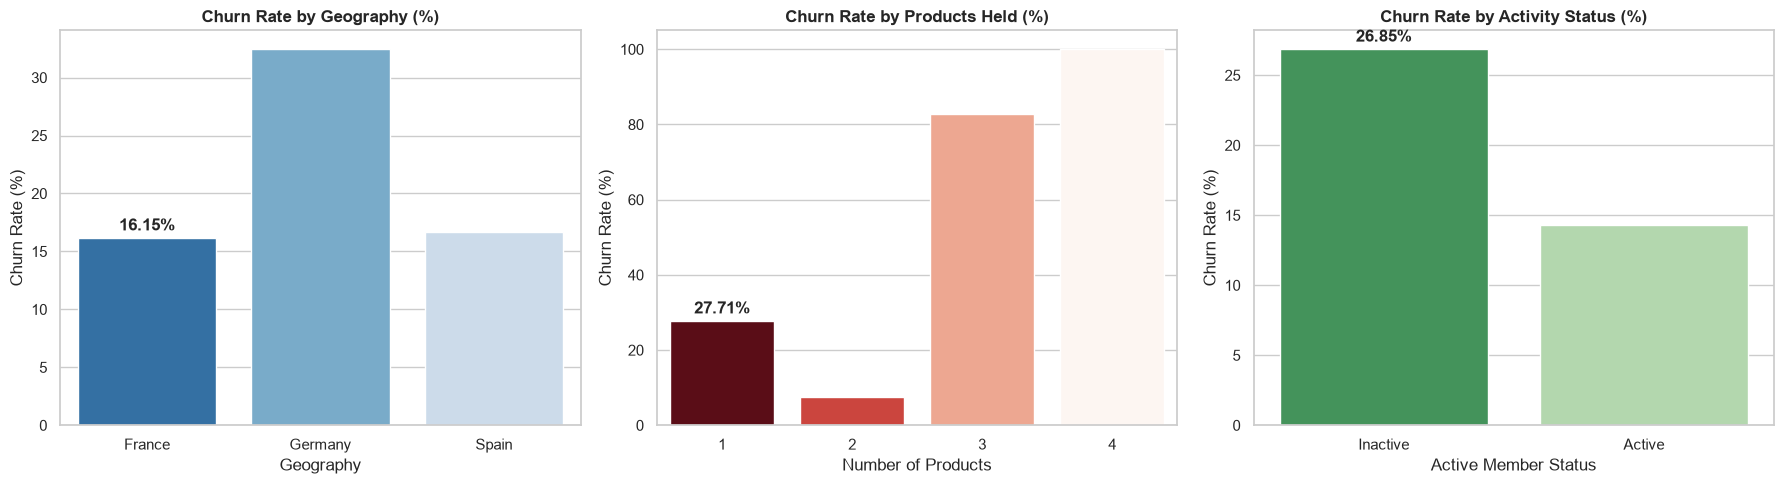

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Churn Rate by Geography
sns.barplot(data=geo_summary, x='geography', y='churn_rate', palette='Blues_r', hue='geography', legend=False, ax=axes[0])
axes[0].set_title('Churn Rate by Geography (%)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_xlabel('Geography')
axes[0].bar_label(axes[0].containers[0], fmt='%.2f%%', padding=3, fontweight='bold')

# 2. Churn Rate by Number of Products Held
sns.barplot(data=product_summary, x='num_of_products', y='churn_rate', palette='Reds_r', hue='num_of_products', legend=False, ax=axes[1])
axes[1].set_title('Churn Rate by Products Held (%)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_xlabel('Number of Products')
axes[1].bar_label(axes[1].containers[0], fmt='%.2f%%', padding=3, fontweight='bold')

# 3. Churn Rate by Activity Status
sns.barplot(data=active_summary, x='is_active_member', y='churn_rate', palette='Greens_r', hue='is_active_member', legend=False, ax=axes[2])
axes[2].set_title('Churn Rate by Activity Status (%)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Churn Rate (%)')
axes[2].set_xlabel('Active Member Status')
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Inactive', 'Active'])
axes[2].bar_label(axes[2].containers[0], fmt='%.2f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.show()

=== CHURN RATE BY AGE COHORT ===
age_group  total_customers  churned_customers  churn_rate
    18-30             1946                146        7.50
    31-40             4451                538       12.09
    41-50             2320                788       33.97
    51-60              797                448       56.21
      60+              464                115       24.78


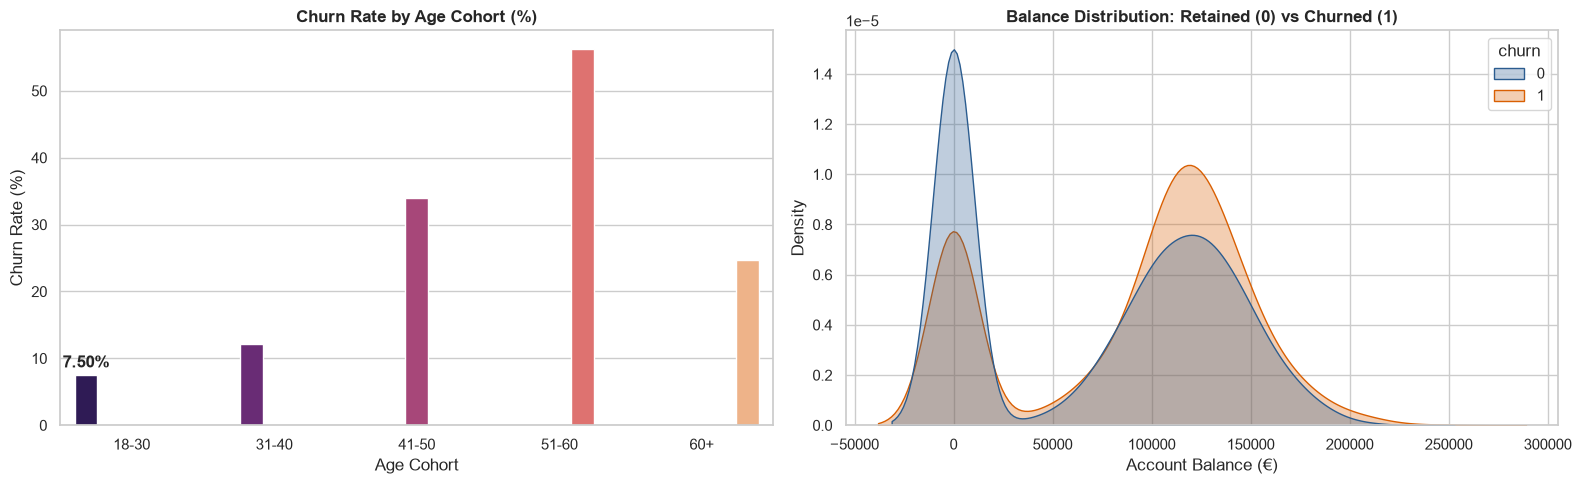

In [8]:
# 1. Create Age Cohort Buckets
df['age_group'] = pd.cut(
    df['age'],
    bins=[18, 30, 40, 50, 60, 100],
    labels=['18-30', '31-40', '41-50', '51-60', '60+']
)

age_summary = df.groupby('age_group', observed=False).agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', 'sum'),
    churn_rate=('churn', lambda x: round(x.mean() * 100, 2))
).reset_index()

print("=== CHURN RATE BY AGE COHORT ===")
print(age_summary.to_string(index=False))

# 2. Visualize Age Cohort Risk and Balance Distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot A: Age Group Churn Rate
sns.barplot(
    data=age_summary,
    x='age_group',
    y='churn_rate',
    palette='magma',
    hue='age_group',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Churn Rate by Age Cohort (%)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_xlabel('Age Cohort')
axes[0].bar_label(axes[0].containers[0], fmt='%.2f%%', padding=3, fontweight='bold')

# Plot B: Balance Distribution (Retained vs Churned)
sns.kdeplot(
    data=df,
    x='balance',
    hue='churn',
    common_norm=False,
    palette=['#2b5c8f', '#d95f02'],
    fill=True,
    alpha=0.3,
    ax=axes[1]
)
axes[1].set_title('Balance Distribution: Retained (0) vs Churned (1)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Account Balance (€)')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.show()

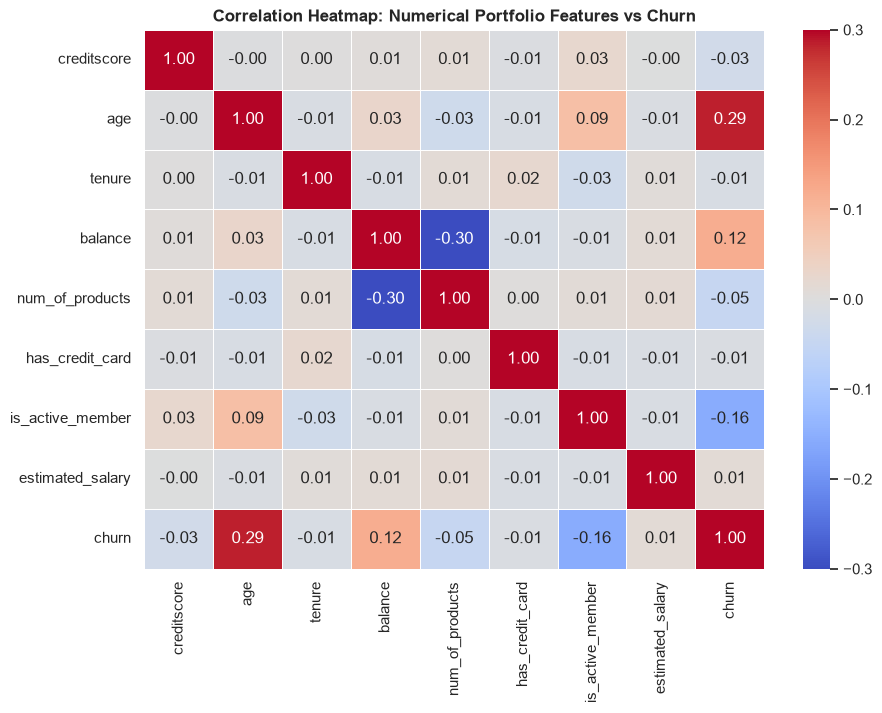

In [9]:
# Select numeric columns for correlation analysis
numeric_cols = [
    'creditscore', 'age', 'tenure', 'balance', 
    'num_of_products', 'has_credit_card', 'is_active_member', 
    'estimated_salary', 'churn'
]

corr_matrix = df[numeric_cols].corr()

# Plot correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-0.3, 
    vmax=0.3, 
    linewidths=0.5
)
plt.title('Correlation Heatmap: Numerical Portfolio Features vs Churn', fontsize=12, fontweight='bold')
plt.show()

In [10]:
# Create the processed directory if it doesn't exist
PROCESSED_PATH = "../data/processed/banking_churn_cleaned.csv"
os.makedirs(os.path.dirname(PROCESSED_PATH), exist_ok=True)

# Export clean DataFrame to data/processed/
df.to_csv(PROCESSED_PATH, index=False)
print(f"Cleaned dataset successfully saved to: {PROCESSED_PATH}")
print(f"Final shape: {df.shape[0]} rows, {df.shape[1]} columns")

Cleaned dataset successfully saved to: ../data/processed/banking_churn_cleaned.csv
Final shape: 10000 rows, 14 columns
